<a href="https://colab.research.google.com/github/HinnaNayab/DeepLearning/blob/Applied-AI/Tutorial_13_Denoising_Autoencoders.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#in tutorial 12 (basic autoencoder), we had a clean image (From MNIST dataset),
#as an input (x_train), ad we tried to reconstruct the same clea output (x_train)
#The problem with a baisc autoencoder is that it just memorizes
#pixel-by-pixel without truly understanding what a "7" or "2" looks like.


#In Tutorial 13, (Denoising autoencoder), we purposely introduce
#TV-static snow (Gaussian noise) & then force the model to output
#a clea same original image

#The network cannot just copy pixels anymore; if it copies the input pixels,
#it copies the static noise and gets penalized.
#To succeed, the Encoder must ignore the random static noise and extract
#only the true underlying shape of the digit, and the Decoder
#must redraw a clean, noise-free digit from scratch.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
#Loading the MNIST Dataset
transform = transforms.ToTensor()
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 37.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.09MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.34MB/s]


In [ ]:
#Noise Generator Function
def add_noise(images, noise_factor=0.5):
    noisy = images + noise_factor * torch.randn_like(images)
    return torch.clamp(noisy, 0.0, 1.0)

In [ ]:
#Denoising Convolutional Autoencoder
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2),
            nn.MaxPool2d(2, 2), # 28 -> 14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2),
            nn.MaxPool2d(2, 2)  # 14 -> 7
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False), # 7 -> 14
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False), # 14 -> 28
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

In [ ]:
#Training on noisy input and forcing a clean reconstructed output

dae_model = DenoisingAutoencoder().to(device)
optimizer = torch.optim.Adam(dae_model.parameters(), lr=1e-3)
criterion = nn.BCELoss()
dae_val_losses = []

for epoch in range(10):
    dae_model.train()
    for clean_imgs, _ in train_loader:
        clean_imgs = clean_imgs.to(device)
        noisy_imgs = add_noise(clean_imgs, noise_factor=0.5)
        optimizer.zero_grad()
        reconstructed = dae_model(noisy_imgs)
        loss = criterion(reconstructed, clean_imgs)
        loss.backward()
        optimizer.step()

    dae_model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for clean_imgs, _ in test_loader:
            clean_imgs = clean_imgs.to(device)
            noisy_imgs = add_noise(clean_imgs, noise_factor=0.5)
            v_loss += criterion(dae_model(noisy_imgs), clean_imgs).item() * clean_imgs.size(0)
    ep_val = v_loss / len(test_dataset)
    dae_val_losses.append(ep_val)
    print(f"[Denoising AE] Epoch {epoch+1:02d}/10 | Val Clean Reconstruction Loss: {ep_val:.4f}")

[Denoising AE] Epoch 01/10 | Val Clean Reconstruction Loss: 0.1184
[Denoising AE] Epoch 02/10 | Val Clean Reconstruction Loss: 0.1093
[Denoising AE] Epoch 03/10 | Val Clean Reconstruction Loss: 0.1043
[Denoising AE] Epoch 04/10 | Val Clean Reconstruction Loss: 0.1019
[Denoising AE] Epoch 05/10 | Val Clean Reconstruction Loss: 0.1003
[Denoising AE] Epoch 06/10 | Val Clean Reconstruction Loss: 0.0989
[Denoising AE] Epoch 07/10 | Val Clean Reconstruction Loss: 0.0986
[Denoising AE] Epoch 08/10 | Val Clean Reconstruction Loss: 0.0978
[Denoising AE] Epoch 09/10 | Val Clean Reconstruction Loss: 0.0968
[Denoising AE] Epoch 10/10 | Val Clean Reconstruction Loss: 0.0972


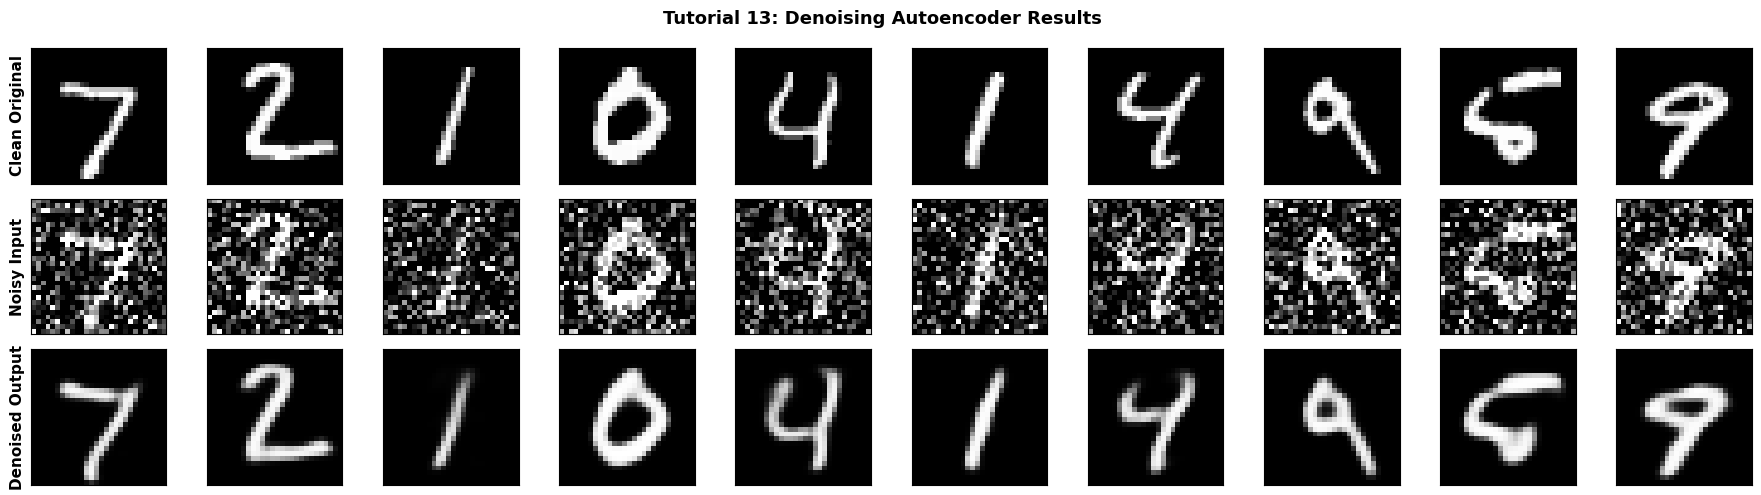

In [14]:
# Visualization of clean vs noisy vs denoised ouput
dae_model.eval()
sample_clean, _ = next(iter(test_loader))
sample_clean = sample_clean[:10]
sample_noisy = add_noise(sample_clean, noise_factor=0.5)
with torch.no_grad():
    sample_denoised = dae_model(sample_noisy.to(device)).cpu()

plt.figure(figsize=(18, 5))
for i in range(10):
    for row, (img_batch, label) in enumerate([(sample_clean, "Clean Original"), (sample_noisy, "Noisy Input"), (sample_denoised, "Denoised Output")]):
        ax = plt.subplot(3, 10, row * 10 + i + 1)
        plt.imshow(img_batch[i, 0], cmap="gray", vmin=0, vmax=1)
        if i == 0: ax.set_ylabel(label, fontsize=11, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Tutorial 13: Denoising Autoencoder Results", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
#Solving for tasks
#Task 1: Implmenetation of Deep autoencoder

class DeepDenoisingAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        # Deep Multi-Layer Convolutional Encoder
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2),  # 28 -> 14
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2), # 14 -> 7
            nn.Conv2d(64, 128, 3, stride=1, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2) # 7 -> 7
        )
        self.fc_enc = nn.Linear(128 * 7 * 7, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, 128 * 7 * 7)

        # Deep Multi-Layer Transposed-Conv Decoder
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 3, stride=1, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.BatchNorm2d(32), nn.LeakyReLU(0.2), # 7 -> 14
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),  # 14 -> 28
            nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder_conv(x).view(x.size(0), -1)
        z = self.fc_enc(h)
        h_dec = self.fc_dec(z).view(x.size(0), 128, 7, 7)
        return self.decoder_conv(h_dec)

deep_dae = DeepDenoisingAutoencoder(latent_dim=32).to(device)
opt_deep = torch.optim.Adam(deep_dae.parameters(), lr=1e-3)
deep_val_losses = []

for epoch in range(10):
    deep_dae.train()
    for clean_imgs, _ in train_loader:
        clean_imgs = clean_imgs.to(device)
        noisy_imgs = add_noise(clean_imgs, noise_factor=0.5)
        opt_deep.zero_grad()
        loss = criterion(deep_dae(noisy_imgs), clean_imgs)
        loss.backward()
        opt_deep.step()

    deep_dae.eval()
    v_loss = 0.0
    with torch.no_grad():
        for clean_imgs, _ in test_loader:
            clean_imgs = clean_imgs.to(device)
            v_loss += criterion(deep_dae(add_noise(clean_imgs, 0.5)), clean_imgs).item() * clean_imgs.size(0)
    ep_val = v_loss / len(test_dataset)
    deep_val_losses.append(ep_val)
    print(f"[Deep Denoising AE] Epoch {epoch+1:02d}/10 | Val Clean Reconstruction Loss: {ep_val:.4f}")

[Deep Denoising AE] Epoch 01/10 | Val Clean Reconstruction Loss: 0.1105
[Deep Denoising AE] Epoch 02/10 | Val Clean Reconstruction Loss: 0.1035
[Deep Denoising AE] Epoch 03/10 | Val Clean Reconstruction Loss: 0.0993
[Deep Denoising AE] Epoch 04/10 | Val Clean Reconstruction Loss: 0.0982
[Deep Denoising AE] Epoch 05/10 | Val Clean Reconstruction Loss: 0.0969
[Deep Denoising AE] Epoch 06/10 | Val Clean Reconstruction Loss: 0.0961
[Deep Denoising AE] Epoch 07/10 | Val Clean Reconstruction Loss: 0.0959
[Deep Denoising AE] Epoch 08/10 | Val Clean Reconstruction Loss: 0.0953
[Deep Denoising AE] Epoch 09/10 | Val Clean Reconstruction Loss: 0.0951
[Deep Denoising AE] Epoch 10/10 | Val Clean Reconstruction Loss: 0.0949


In [13]:
#Task 2: Variational autoencoder

class VariationalAutoencoder(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.LeakyReLU(0.2), # 28 -> 14
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.LeakyReLU(0.2) # 14 -> 7
        )
        # Predicts BOTH Mean (mu) and Log-Variance (logvar)
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_dec = nn.Linear(latent_dim, 64 * 7 * 7)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.LeakyReLU(0.2), # 7 -> 14
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),  # 14 -> 28
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x).view(x.size(0), -1)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(self.fc_dec(z).view(x.size(0), 64, 7, 7))
        return recon, mu, logvar

# VAE Loss = Reconstruction Loss (BCE) + KL Divergence (keeps latent space smooth)
def vae_loss_fn(recon_x, x, mu, logvar):
    bce = F.binary_cross_entropy(recon_x, x, reduction="sum")
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (bce + kld) / x.size(0)

vae_model = VariationalAutoencoder(latent_dim=16).to(device)
opt_vae = torch.optim.Adam(vae_model.parameters(), lr=1e-3)

for epoch in range(10):
    vae_model.train()
    tr_loss = 0.0
    for clean_imgs, _ in train_loader:
        clean_imgs = clean_imgs.to(device)
        noisy_imgs = add_noise(clean_imgs, noise_factor=0.5)
        opt_vae.zero_grad()
        recon, mu, logvar = vae_model(noisy_imgs)
        loss = vae_loss_fn(recon, clean_imgs, mu, logvar)
        loss.backward()
        opt_vae.step()
        tr_loss += loss.item() * clean_imgs.size(0)
    print(f"[Variational AE (VAE)] Epoch {epoch+1:02d}/10 | Train ELBO Loss: {tr_loss/len(train_dataset):.2f}")

[Variational AE (VAE)] Epoch 01/10 | Train ELBO Loss: 176.00
[Variational AE (VAE)] Epoch 02/10 | Train ELBO Loss: 136.45
[Variational AE (VAE)] Epoch 03/10 | Train ELBO Loss: 129.66
[Variational AE (VAE)] Epoch 04/10 | Train ELBO Loss: 125.42
[Variational AE (VAE)] Epoch 05/10 | Train ELBO Loss: 123.06
[Variational AE (VAE)] Epoch 06/10 | Train ELBO Loss: 121.64
[Variational AE (VAE)] Epoch 07/10 | Train ELBO Loss: 120.68
[Variational AE (VAE)] Epoch 08/10 | Train ELBO Loss: 119.81
[Variational AE (VAE)] Epoch 09/10 | Train ELBO Loss: 119.27
[Variational AE (VAE)] Epoch 10/10 | Train ELBO Loss: 118.78
